# Component detection by the component-aware model

Model `multitask_all` (all training writers), component probabilities on the 60,723 test images
from `results/E01_baseline_vs_components/multitask_all/test_predictions.npz` (experiment E01). A label counts as predicted when its
probability is at least 0.5. Questions:

1. How well is each component label detected (precision, recall, F1)?
2. For how many images is the whole set of positioned components right?
3. What does the prediction look like for single images?

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "src")
from kanji_components.etl9b import Etl9bCache

RESULTS_DIR = Path("results/E01_baseline_vs_components")
RUN = "multitask_all"
THRESHOLD = 0.5

In [2]:
SERIES_BLUE = "#2a78d6"
TEXT_SECONDARY = "#52514e"
GRID_GRAY = "#e6e5e1"

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRID_GRAY,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID_GRAY,
    "axes.axisbelow": True,
    "font.family": ["Noto Sans CJK JP", "DejaVu Sans"],
})

In [3]:
archive = np.load("data/component_targets_df5.npz", allow_pickle=False)
characters = list(archive["characters"])
vocabulary = {"nested": list(archive["nested_vocabulary"]), "positioned": list(archive["positioned_vocabulary"])}
predictions = np.load(RESULTS_DIR / RUN / "test_predictions.npz")
labels = predictions["labels"].astype(int)
probabilities = {name: predictions[f"{name}_probabilities"].astype(np.float32) for name in vocabulary}
targets = {name: archive[f"{name}_targets"][labels] > 0.5 for name in vocabulary}
print(len(labels), "test images;", {name: len(words) for name, words in vocabulary.items()})

60723 test images; {'nested': 382, 'positioned': 251}


## 1. Per-label detection quality

⚠️ Threshold 0.5 on the sigmoid probability. Training used positive weights up to 20, which pushes
probabilities of rare labels up, so a lower threshold would trade precision for recall.

In [4]:
def per_label_table(name):
    predicted = probabilities[name] >= THRESHOLD
    actual = targets[name]
    true_positive = (predicted & actual).sum(0)
    precision = true_positive / np.maximum(predicted.sum(0), 1)
    recall = true_positive / np.maximum(actual.sum(0), 1)
    f1 = 2 * true_positive / np.maximum(predicted.sum(0) + actual.sum(0), 1)
    return pd.DataFrame({"head": name, "label": vocabulary[name], "test_images_with_label": actual.sum(0),
                         "classes_with_label": (archive[f"{name}_targets"] > 0.5).sum(0),
                         "precision": precision, "recall": recall, "f1": f1})


per_label = pd.concat([per_label_table(name) for name in vocabulary], ignore_index=True)
per_label.to_csv(RESULTS_DIR / RUN / "component_detection_per_label.csv", index=False)
print("saved", RESULTS_DIR / RUN / "component_detection_per_label.csv", len(per_label), "labels")
per_label.groupby("head")[["precision", "recall", "f1"]].agg(["mean", "median"]).round(3)

saved results/E01_baseline_vs_components/multitask_all/component_detection_per_label.csv 633 labels


precision        recall            f1       
                mean median   mean median   mean median
head                                                   
nested         0.580  0.586  0.937  0.952  0.704  0.727
positioned     0.669  0.686  0.963  0.977  0.778  0.806

In [5]:
summary_rows = []
for name in vocabulary:
    predicted = probabilities[name] >= THRESHOLD
    actual = targets[name]
    true_positive = (predicted & actual).sum()
    summary_rows.append({"head": name, "micro_precision": true_positive / predicted.sum(),
                         "micro_recall": true_positive / actual.sum(),
                         "micro_f1": 2 * true_positive / (predicted.sum() + actual.sum()),
                         "labels_with_f1_above_0.8": int((per_label[per_label["head"] == name]["f1"] > 0.8).sum()),
                         "labels_with_f1_below_0.5": int((per_label[per_label["head"] == name]["f1"] < 0.5).sum())})
pd.DataFrame(summary_rows).set_index("head").round(3)

,micro_precision,micro_recall,micro_f1,labels_with_f1_above_0.8,labels_with_f1_below_0.5
head,,,,,
nested,0.420,0.893,0.571,116,41
positioned,0.599,0.965,0.739,132,12


In [6]:
positioned = per_label[per_label["head"] == "positioned"].sort_values("f1", ascending=False)
print("best detected positioned components")
positioned.head(15)[["label", "test_images_with_label", "classes_with_label", "precision", "recall", "f1"]]

best detected positioned components


,label,test_images_with_label,classes_with_label,precision,recall,f1
623,粦@right,90,5,0.989011,1.000000,0.994475
579,㐮@right,115,5,0.974576,1.000000,0.987124
537,虍@tare,145,7,0.947712,1.000000,0.973154
600,它@right,86,5,0.955056,0.988372,0.971429
625,翟@right,85,5,0.954545,0.988235,0.971098
434,酉@left,366,17,0.938144,0.994536,0.965517
573,走@nyo,134,6,0.924138,1.000000,0.960573
524,支@right,152,7,0.915663,1.000000,0.955975
624,羊@right,104,5,0.919643,0.990385,0.953704
620,矢@left,99,5,0.915888,0.989899,0.951456


In [7]:
print("worst detected positioned components")
positioned.tail(15)[["label", "test_images_with_label", "classes_with_label", "precision", "recall", "f1"]]

worst detected positioned components


,label,test_images_with_label,classes_with_label,precision,recall,f1
485,亠@none,184,9,0.361345,0.934783,0.521212
406,冖@none,551,28,0.358673,0.941924,0.519520
472,儿@none,180,10,0.365517,0.883333,0.517073
467,辶@nyo,220,12,0.329738,0.972727,0.492520
436,十@none,328,16,0.346154,0.740854,0.471845
464,大@none,231,12,0.313856,0.813853,0.453012
443,八@none,303,15,0.305725,0.828383,0.446619
414,丨@none,452,22,0.281227,0.831858,0.420347
428,日@none,349,18,0.271107,0.828080,0.408481
457,人@none,268,13,0.272050,0.817164,0.408201


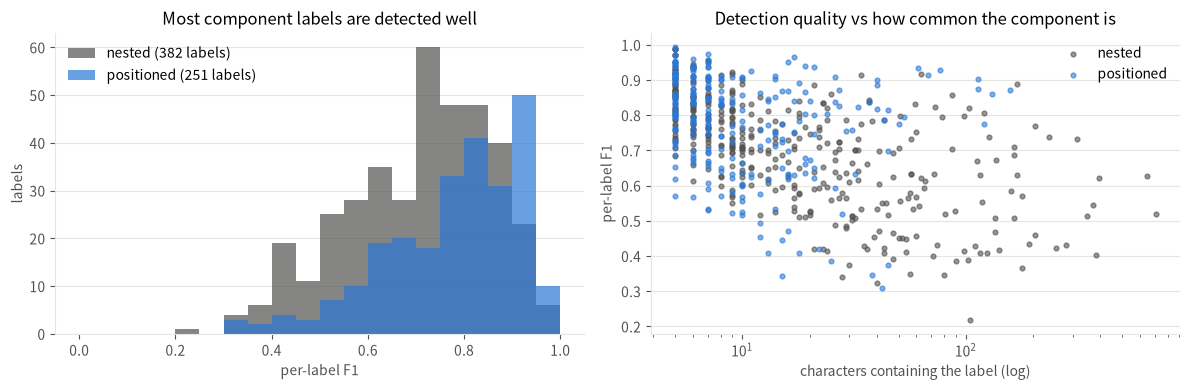

In [8]:
figure, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
for name, color in [("nested", TEXT_SECONDARY), ("positioned", SERIES_BLUE)]:
    subset = per_label[per_label["head"] == name]
    left.hist(subset["f1"], bins=20, range=(0, 1), alpha=0.7, color=color, label=f"{name} ({len(subset)} labels)")
    right.scatter(subset["classes_with_label"], subset["f1"], s=12, alpha=0.6, color=color, label=name)
left.set_xlabel("per-label F1")
left.set_ylabel("labels")
left.set_title("Most component labels are detected well")
left.legend(frameon=False)
right.set_xscale("log")
right.set_xlabel("characters containing the label (log)")
right.set_ylabel("per-label F1")
right.set_title("Detection quality vs how common the component is")
right.legend(frameon=False)
plt.tight_layout()

In [9]:
position_of = positioned["label"].str.split("@").str[1]
by_position = positioned.assign(position=position_of.values).groupby("position").agg(
    labels=("label", "size"), test_images=("test_images_with_label", "sum"), mean_f1=("f1", "mean"))
by_position.sort_values("labels", ascending=False).round(3)

,labels,test_images,mean_f1
position,,,
right,72,11478,0.881
none,55,12506,0.610
left,47,28565,0.848
top,33,9207,0.752
bottom,27,6815,0.719
kamae,7,1196,0.899
tare,6,1824,0.782
nyo,4,1466,0.799


## 2. Whole-image correctness

In [10]:
predicted_sets = probabilities["positioned"] >= THRESHOLD
has_target = targets["positioned"].any(1)
exact_match = (predicted_sets == targets["positioned"]).all(1)
at_least_one = (predicted_sets & targets["positioned"]).any(1)
no_false_positive = ~(predicted_sets & ~targets["positioned"]).any(1)
print(f"images with at least one positioned target: {has_target.sum()} of {len(labels)}")
print(f"  whole positioned set exactly right: {exact_match[has_target].mean():.1%}")
print(f"  at least one true component found:  {at_least_one[has_target].mean():.1%}")
print(f"  no wrong component predicted:       {no_false_positive[has_target].mean():.1%}")

images with at least one positioned target: 53884 of 60723
  whole positioned set exactly right: 50.7%
  at least one true component found:  98.3%
  no wrong component predicted:       52.5%


Hypothesis: exact-set accuracy is bounded by the one-component-per-character labels (e.g. 樋 is only
"木@left"), where a single extra detection of a true but unlabelled part counts as an error.

## 3. Single images: true vs predicted components

In [11]:
cache = Etl9bCache()
assert cache.characters == characters
test_indices = predictions["indices"]
print(cache.images.shape)

(607200, 64, 64)


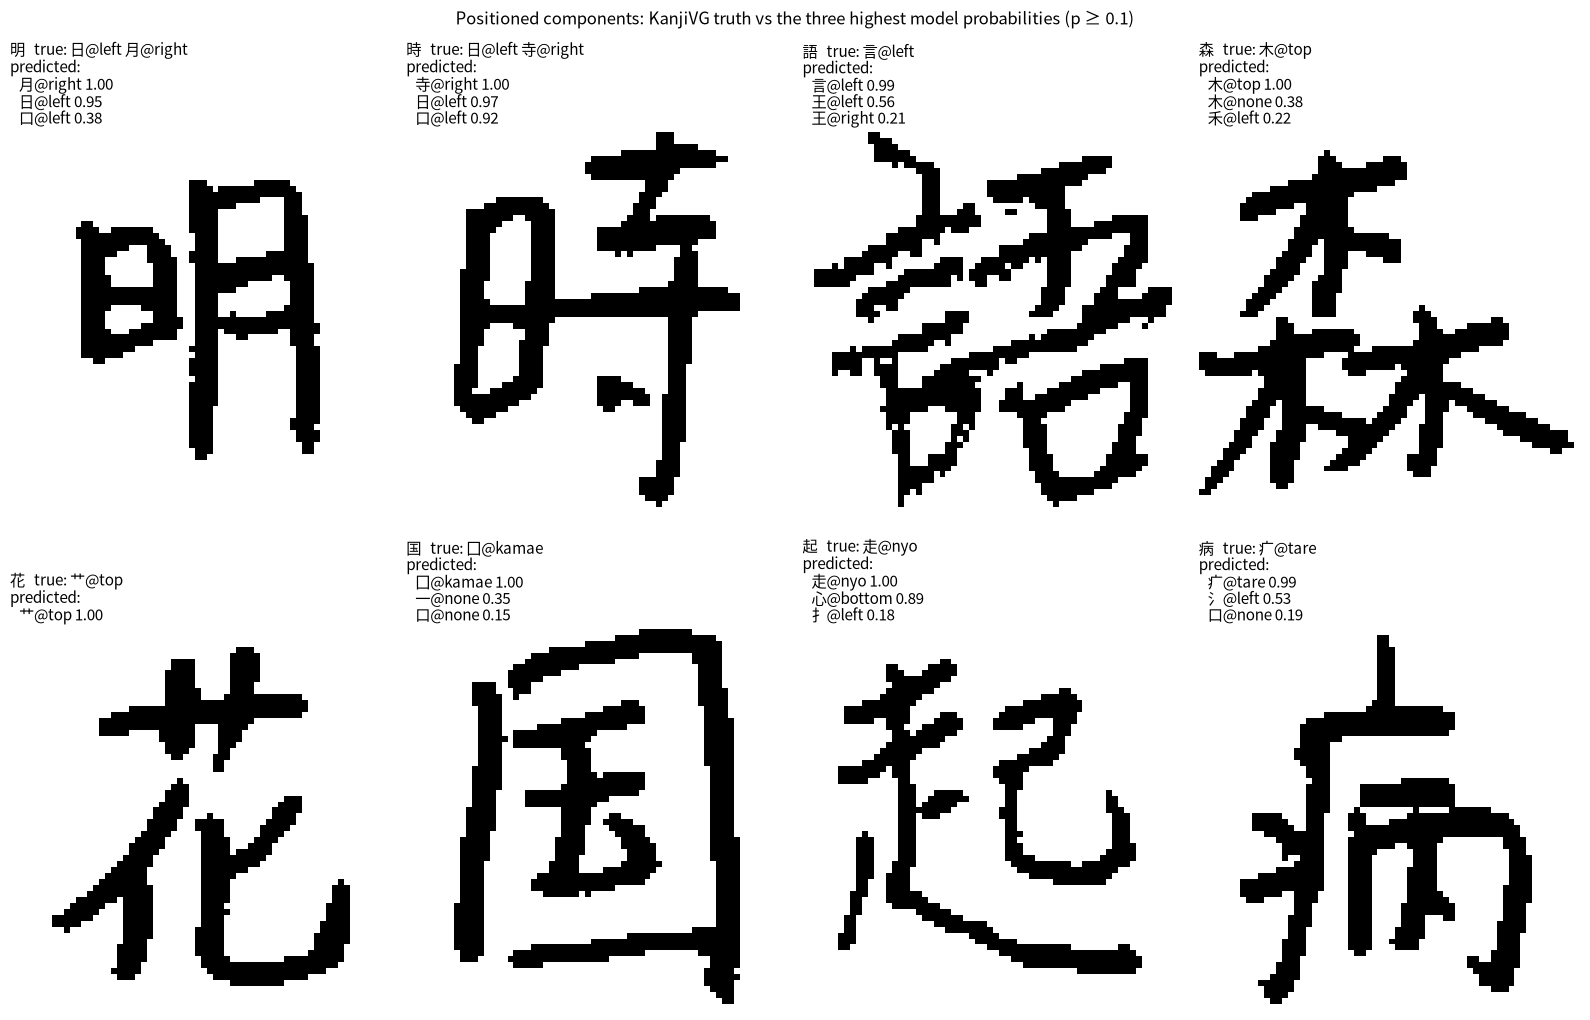

In [12]:
def describe(name, row, limit=4, separator=", "):
    order = np.argsort(-probabilities[name][row])[:limit]
    return separator.join(f"{vocabulary[name][i]} {probabilities[name][row, i]:.2f}" for i in order
                          if probabilities[name][row, i] >= 0.1)


def glyph_title(row):
    character = characters[labels[row]]
    predicted = describe("positioned", row, limit=3, separator="\n   ")
    return f"{character}   true: {true_labels('positioned', row)}\npredicted:\n   {predicted}"


def true_labels(name, row):
    return " ".join(vocabulary[name][i] for i in np.flatnonzero(targets[name][row]))


EXAMPLE_CHARACTERS = ["明", "時", "語", "森", "花", "国", "起", "病"]
example_rows = [np.flatnonzero(labels == characters.index(character))[0] for character in EXAMPLE_CHARACTERS]
figure, axes = plt.subplots(2, 4, figsize=(16, 11))
for axis, row in zip(axes.ravel(), example_rows):
    axis.imshow(cache.images[test_indices[row]], cmap="gray_r")
    axis.set_title(glyph_title(row), fontsize=11, loc="left")
    axis.axis("off")
figure.suptitle("Positioned components: KanjiVG truth vs the three highest model probabilities (p ≥ 0.1)")
plt.tight_layout()

In [13]:
examples = pd.DataFrame({
    "character": EXAMPLE_CHARACTERS,
    "true nested": [true_labels("nested", row) for row in example_rows],
    "predicted nested (p ≥ 0.1)": [describe("nested", row, limit=6) for row in example_rows],
})
pd.set_option("display.max_colwidth", 120)
examples

,character,true nested,predicted nested (p ≥ 0.1)
0,明,日 月,"月 1.00, 肉 0.98, 目 0.95, 日 0.87, 廾 0.56, 一 0.51"
1,時,日 土 寸 寺,"寺 1.00, 寸 0.99, 亅 0.94, 土 0.92, 丁 0.69, 一 0.62"
2,語,口 二 言 五,"言 1.00, 五 0.99, 口 0.98, 士 0.95, 舌 0.86, 千 0.77"
3,森,木 林,"木 1.00, 禾 0.99, 林 0.97, 米 0.70, 丿 0.69, 大 0.59"
4,花,人 亻 艸 艹 匕,"艹 1.00, 艸 1.00, 儿 0.97, 匕 0.96, 亻 0.96, 人 0.79"
5,国,丶 玉 王 囗,"囗 0.99, 寸 0.86, 一 0.69, 王 0.69, 玉 0.69, 尸 0.56"
6,起,土 己 龰 走,"走 1.00, 龰 1.00, 己 0.99, 匕 0.77, 二 0.75, 儿 0.73"
7,病,人 一 冂 疒,"疒 0.99, 冂 0.93, 亠 0.85, 口 0.74, 一 0.67, 厂 0.53"


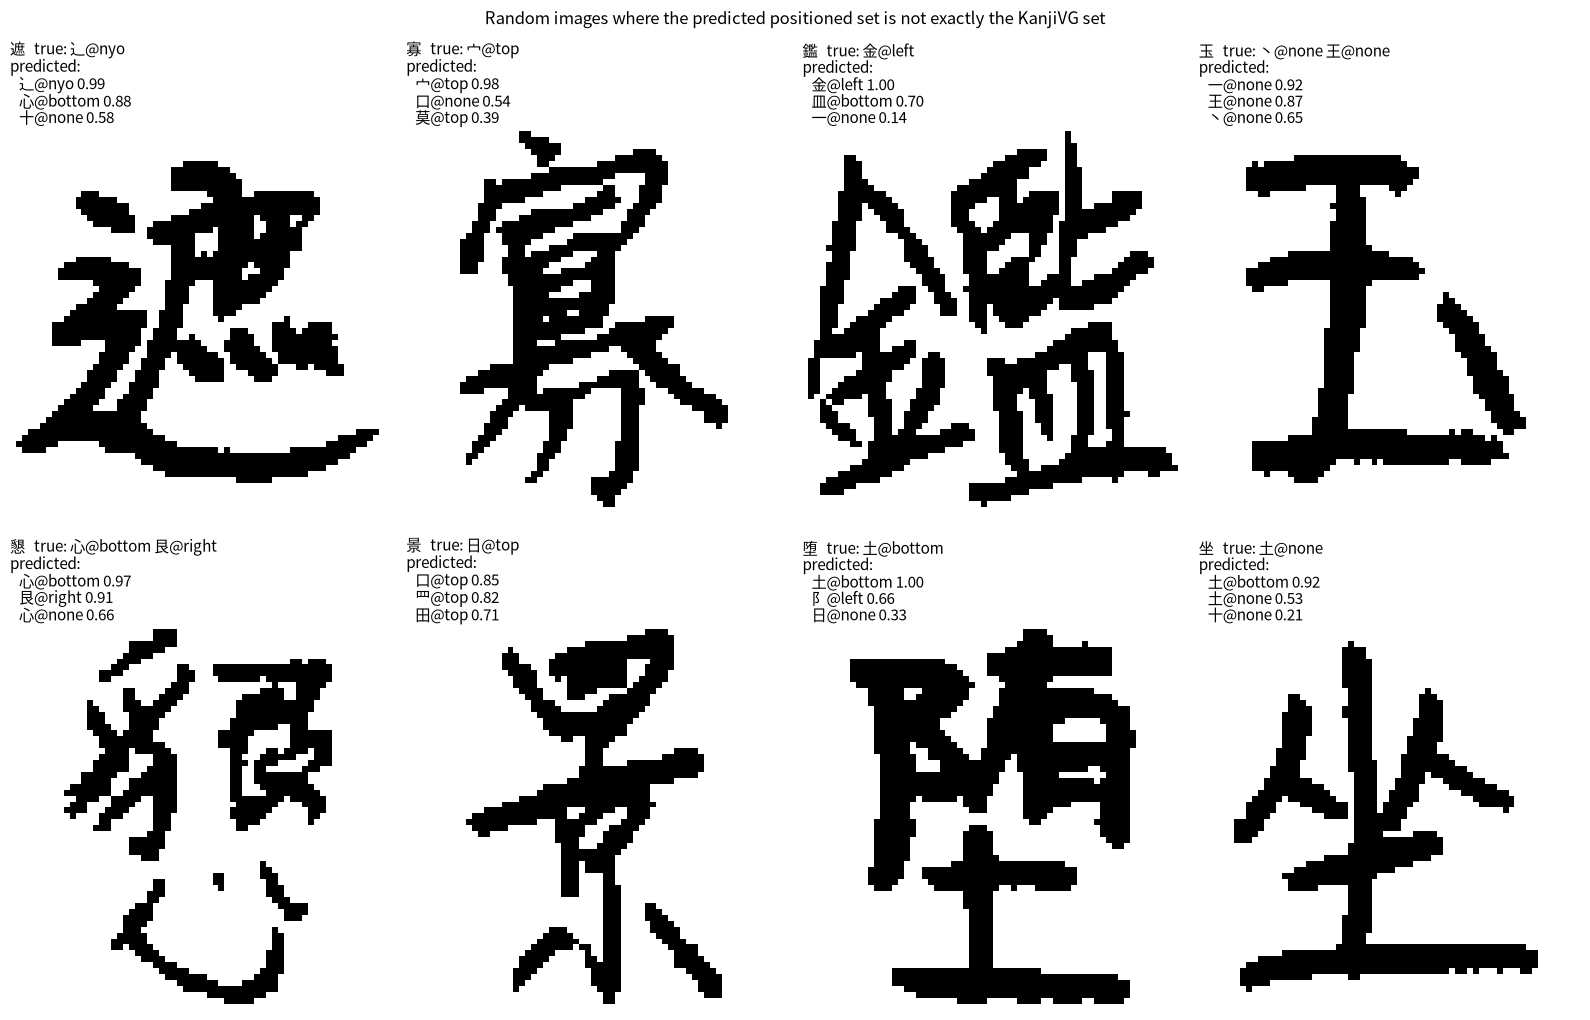

In [14]:
wrong_rows = np.flatnonzero(has_target & ~exact_match)
sample_rows = np.random.default_rng(0).choice(wrong_rows, 8, replace=False)
figure, axes = plt.subplots(2, 4, figsize=(16, 11))
for axis, row in zip(axes.ravel(), sample_rows):
    axis.imshow(cache.images[test_indices[row]], cmap="gray_r")
    axis.set_title(glyph_title(row), fontsize=11, loc="left")
    axis.axis("off")
figure.suptitle("Random images where the predicted positioned set is not exactly the KanjiVG set")
plt.tight_layout()